# **EN3160 Image Processing & Computer Vision - Assignment 02**


**Name : Meedeniya M.M.H**  
**Index No. : 230407K**

### **Github Repository** : https://github.com/manjarimeedeniya/EN3160-Assignment-2

### Question 1

In [2]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

sigma range: 1.5 to 11.1, 38 blobs
largest: x=0, y=275, r=10.9, sigma=7.7
largest: x=282, y=338, r=10.9, sigma=7.7
largest: x=179, y=327, r=9.1, sigma=6.4
largest: x=106, y=255, r=7.6, sigma=5.4
largest: x=178, y=261, r=7.6, sigma=5.4


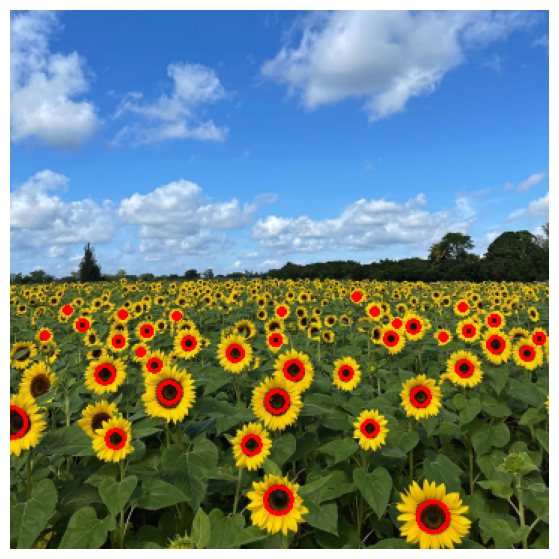

In [25]:
im = cv.imread(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
g = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255

sigmas = 1.5 * 1.2 ** np.arange(12)    
sign = +1                              
rel_thresh = 0.8                      

L = np.stack([sign * s**2 * cv.Laplacian(cv.GaussianBlur(g, (0, 0), s), cv.CV_32F)
              for s in sigmas])

peaks = (L == maximum_filter(L, size=(3, 7, 7))) & (L > rel_thresh * L.max())

k, y, x = np.nonzero(peaks)
r = np.sqrt(2) * sigmas[k]

print(f'sigma range: {sigmas[0]:.1f} to {sigmas[-1]:.1f}, {len(r)} blobs')
for i in np.argsort(-r)[:5]:
    print(f'largest: x={x[i]}, y={y[i]}, r={r[i]:.1f}, sigma={sigmas[k[i]]:.1f}')

out = cv.cvtColor(im, cv.COLOR_BGR2RGB).copy()
for xi, yi, ri in zip(x, y, r):
    cv.circle(out, (int(xi), int(yi)), int(ri), (255, 0, 0), 2)
plt.figure(figsize=(10, 7)); plt.imshow(out); plt.axis('off'); plt.show()

### Discussion  
* In this activity, the scale-space Laplacian of Gaussian method detected $38$ sunflower centers across the image. The largest detected circles have radii of approximately $10.9$ pixels.  
* At the begining when tried with lower threshold values, the detector introduced several false positives in the sky and background trees. This occurs because the Laplacian of Gaussian operator responds purely to intensity curvature.  
* Also These results clearly show how depth affects scale in the image. The sunflowers in the foreground near the bottom appear much larger, so they peak at higher $\sigma$ values and produce larger circles. As you look toward the background, the flowers appear smaller and are caught at lower $\sigma$ values

### Question 2


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

np.random.seed(0)
N = 100
half_n = N // 2

# Ground truth circle
r_gt = 10.0
x0_gt, y0_gt = 2.0, 3.0
s_circ = r_gt / 16.0
t = np.random.uniform(0, 2 * np.pi, half_n)
n_circ = s_circ * np.random.randn(half_n)
x_circ = x0_gt + (r_gt + n_circ) * np.cos(t)
y_circ = y0_gt + (r_gt + n_circ) * np.sin(t)
X_circ = np.column_stack((x_circ, y_circ))

# Ground truth line: y = m*x + b -> -m*x + y - b = 0
s_line = 1.0
m_gt, b_gt = -1.0, 2.0
x_line = np.linspace(-12, 12, half_n)
y_line = m_gt * x_line + b_gt + s_line * np.random.randn(half_n)
X_line = np.column_stack((x_line, y_line))

# Combined noisy point set (100 points total)
X = np.vstack((X_circ, X_line))

In [ ]:
# Line Solvers
def line_from_two_points(p1, p2):
    dx, dy = p2[0] - p1[0], p2[1] - p1[1]
    norm = np.hypot(dx, dy)
    if norm < 1e-12:
        return None
    a, b = dy / norm, -dx / norm
    d = a * p1[0] + b * p1[1]
    return np.array([a, b, d])

def line_errors(params, pts):
    a, b, d = params
    return np.abs(a * pts[:, 0] + b * pts[:, 1] - d)

def fit_line_tls(pts):
    mean = pts.mean(axis=0)
    _, _, Vt = np.linalg.svd(pts - mean)
    normal = Vt[-1]
    p0 = np.array([normal[0], normal[1], normal @ mean])

    def cost(p):
        return np.sum((p[0] * pts[:, 0] + p[1] * pts[:, 1] - p[2]) ** 2)

    cons = {'type': 'eq', 'fun': lambda p: p[0]**2 + p[1]**2 - 1}
    res = minimize(cost, p0, constraints=cons, method='SLSQP')
    p = res.x
    p[:2] /= np.linalg.norm(p[:2])
    return p

#Circle Solvers
def circle_from_three_points(p1, p2, p3):
    ax, ay = p1
    bx, by = p2
    cx, cy = p3
    D = 2 * (ax * (by - cy) + bx * (cy - ay) + cx * (ay - by))
    if abs(D) < 1e-9:
        return None
    ux = ((ax**2 + ay**2)*(by - cy) + (bx**2 + by**2)*(cy - ay) + (cx**2 + cy**2)*(ay - by)) / D
    uy = ((ax**2 + ay**2)*(cx - bx) + (bx**2 + by**2)*(ax - cx) + (cx**2 + cy**2)*(bx - ax)) / D
    rad = np.hypot(ax - ux, ay - uy)
    return np.array([ux, uy, rad])

def circle_errors(params, pts):
    cx, cy, rad = params
    return np.abs(np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) - rad)

def fit_circle_opt(pts, p0):
    def cost(p):
        return np.sum(circle_errors(p, pts) ** 2)
    res = minimize(cost, p0, method='Nelder-Mead',
                    options={'xatol': 1e-8, 'fatol': 1e-10, 'maxiter': 5000})
    return res.x

In [28]:
def ransac_line(pts, thresh, min_inliers, iters=1000):
    best = {'count': -1}
    n_pts = len(pts)
    for _ in range(iters):
        idx = np.random.choice(n_pts, 2, replace=False)
        model = line_from_two_points(pts[idx[0]], pts[idx[1]])
        if model is None:
            continue
        mask = line_errors(model, pts) < thresh
        count = mask.sum()
        if count > best['count']:
            best = {'count': count, 'mask': mask, 'idx': idx, 'sample_model': model}

    if best['count'] < min_inliers:
        raise RuntimeError("Line consensus not reached")

    refined = fit_line_tls(pts[best['mask']])
    mask = line_errors(refined, pts) < thresh
    return refined, mask, best['idx'], best['sample_model']

# Execution for 2(a)
LINE_THRESH = 1.5
LINE_MIN_INLIERS = 35
line_best, line_mask, line_sample_idx, line_sample_model = ransac_line(
    X, LINE_THRESH, LINE_MIN_INLIERS, iters=2000
)

a, b, d = line_best
print("Part (a) Results:")
print(f"Estimated [a, b]: [{a:.4f}, {b:.4f}], Constraint norm: {np.hypot(a, b):.6f}")
print(f"Perpendicular distance d: {d:.4f}")
print(f"Slope: {-a/b:.4f} (gt: {m_gt}), Intercept: {d/b:.4f} (gt: {b_gt})")
print(f"Line inliers: {line_mask.sum()} / {len(X)}")

Part (a) Results:
Estimated [a, b]: [0.7181, 0.6959], Constraint norm: 1.000000
Perpendicular distance d: 1.5222
Slope: -1.0320 (gt: -1.0), Intercept: 2.1874 (gt: 2.0)
Line inliers: 54 / 100


In [29]:
def ransac_circle(pts, thresh, min_inliers, iters=1000):
    best = {'count': -1}
    n_pts = len(pts)
    for _ in range(iters):
        idx = np.random.choice(n_pts, 3, replace=False)
        model = circle_from_three_points(*pts[idx])
        if model is None:
            continue
        mask = circle_errors(model, pts) < thresh
        count = mask.sum()
        if count > best['count']:
            best = {'count': count, 'mask': mask, 'idx': idx, 'sample_model': model}

    if best['count'] < min_inliers:
        raise RuntimeError("Circle consensus not reached")

    refined = fit_circle_opt(pts[best['mask']], best['sample_model'])
    mask = circle_errors(refined, pts) < thresh
    return refined, mask, best['idx'], best['sample_model']

# Execution for 2(b)
X_remnant = X[~line_mask]
CIRCLE_THRESH = 1.0
CIRCLE_MIN_INLIERS = 35
circle_best, circle_mask, circ_sample_idx, circ_sample_model = ransac_circle(
    X_remnant, CIRCLE_THRESH, CIRCLE_MIN_INLIERS, iters=2000
)

print("Part (b) Results:")
print(f"Estimated Center: ({circle_best[0]:.4f}, {circle_best[1]:.4f}) (gt: {x0_gt}, {y0_gt})")
print(f"Estimated Radius: {circle_best[2]:.4f} (gt: {r_gt})")
print(f"Circle inliers: {circle_mask.sum()} / {len(X_remnant)}")

Part (b) Results:
Estimated Center: (1.8799, 2.9642) (gt: 2.0, 3.0)
Estimated Radius: 9.8668 (gt: 10.0)
Circle inliers: 43 / 46


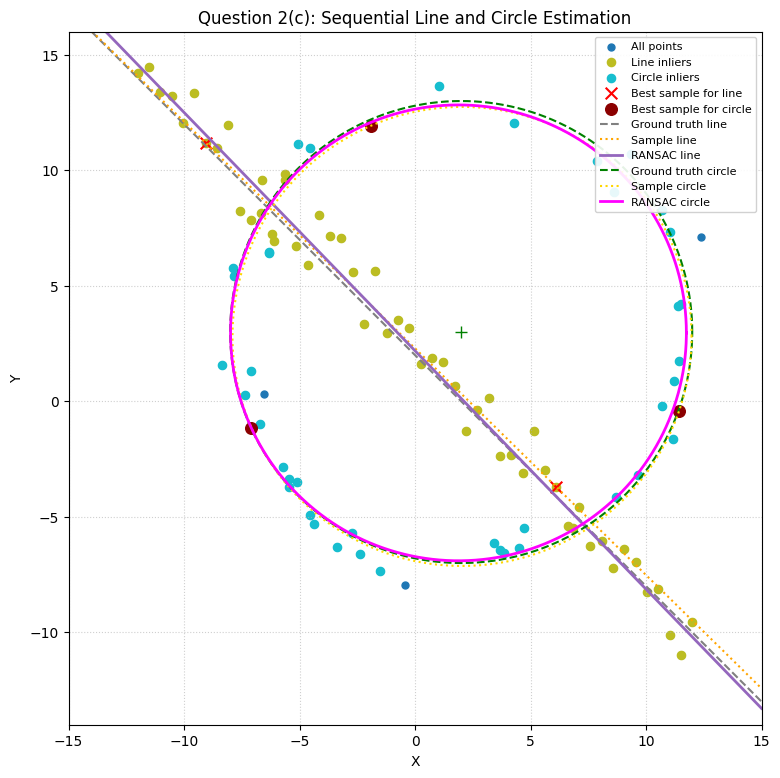

In [30]:
fig, ax = plt.subplots(1, 1, figsize=(9, 9))

# Base point clouds
ax.scatter(X[:, 0], X[:, 1], s=25, color='#1f77b4', label='All points')
ax.scatter(X[line_mask, 0], X[line_mask, 1], s=35, color='#bcbd22', label='Line inliers')
ax.scatter(X_remnant[circle_mask, 0], X_remnant[circle_mask, 1], s=35, color='#17becf', label='Circle inliers')

#Minimal sample points
ax.scatter(X[line_sample_idx, 0], X[line_sample_idx, 1], s=70, marker='x', color='red', label='Best sample for line')
ax.scatter(X_remnant[circ_sample_idx, 0], X_remnant[circ_sample_idx, 1], s=70, marker='o', color='darkred', label='Best sample for circle')

# Geometric curves (Lines)
xs = np.array([-15, 15])
ys_fit = (line_best[2] - line_best[0] * xs) / line_best[1]
ys_sample = (line_sample_model[2] - line_sample_model[0] * xs) / line_sample_model[1]
ys_gt = m_gt * xs + b_gt

ax.plot(xs, ys_gt, color='gray', linestyle='--', linewidth=1.5, label='Ground truth line')
ax.plot(xs, ys_sample, color='orange', linestyle=':', linewidth=1.5, label='Sample line')
ax.plot(xs, ys_fit, color='#9467bd', linewidth=2.0, label='RANSAC line')

# Geometric curves (Circles)
theta = np.linspace(0, 2 * np.pi, 400)
# Ground truth circle
ax.plot(x0_gt + r_gt * np.cos(theta), y0_gt + r_gt * np.sin(theta),
        color='green', linestyle='--', linewidth=1.5, label='Ground truth circle')
# Best sample circle
ax.plot(circ_sample_model[0] + circ_sample_model[2] * np.cos(theta),
        circ_sample_model[1] + circ_sample_model[2] * np.sin(theta),
        color='gold', linestyle=':', linewidth=1.5, label='Sample circle')
# Best refined circle
ax.plot(circle_best[0] + circle_best[2] * np.cos(theta),
        circle_best[1] + circle_best[2] * np.sin(theta),
        color='magenta', linewidth=2.0, label='RANSAC circle')

ax.plot(x0_gt, y0_gt, '+', color='green', markersize=8)
ax.set_aspect('equal')
ax.set_xlim(-15, 15)
ax.set_ylim(-14, 16)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right', framealpha=0.9, fontsize=8)
plt.title('Question 2(c): Sequential Line and Circle Estimation')
plt.show()

Part (d) - Circle Fitted First:
Center: (1.96, 2.88) | Radius: 9.83
Inliers count: 59 / 100


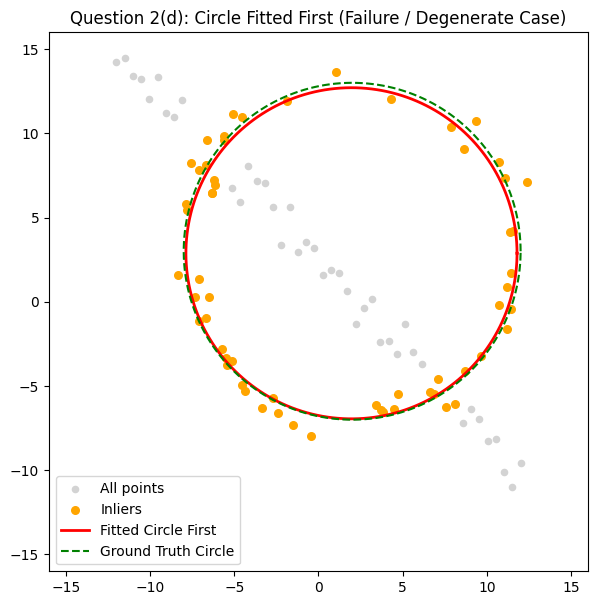

In [31]:
# Trying fitting circle directly on all 100 points
np.random.seed(42)
circ_first, circ_first_mask, cf_idx, _ = ransac_circle(X, thresh=1.5, min_inliers=25, iters=2000)

print("Part (d) - Circle Fitted First:")
print(f"Center: ({circ_first[0]:.2f}, {circ_first[1]:.2f}) | Radius: {circ_first[2]:.2f}")
print(f"Inliers count: {circ_first_mask.sum()} / 100")

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(X[:, 0], X[:, 1], c='lightgray', s=20, label='All points')
ax.scatter(X[circ_first_mask, 0], X[circ_first_mask, 1], c='orange', s=30, label='Inliers')
ax.plot(circ_first[0] + circ_first[2]*np.cos(theta),
        circ_first[1] + circ_first[2]*np.sin(theta), 'r-', lw=2, label='Fitted Circle First')
ax.plot(x0_gt + r_gt*np.cos(theta), y0_gt + r_gt*np.sin(theta), 'g--', label='Ground Truth Circle')
ax.set_aspect('equal')
ax.set_xlim(-16, 16)
ax.set_ylim(-16, 16)
ax.legend()
plt.title('Question 2(d): Circle Fitted First (Failure / Degenerate Case)')
plt.show()

## Question 3

H =
 [[ 2.90e-02 -1.10e-02  2.25e+02]
 [-2.10e-01  4.59e-01  1.74e+02]
 [-1.00e-03 -0.00e+00  1.00e+00]]


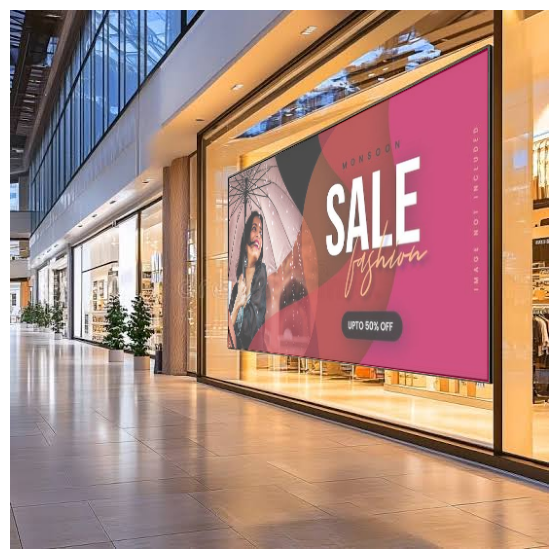

H =
 [[ 2.76e-01 -1.40e-02  5.10e+01]
 [ 9.90e-02  1.80e-01  3.30e+01]
 [ 1.00e-03 -0.00e+00  1.00e+00]]


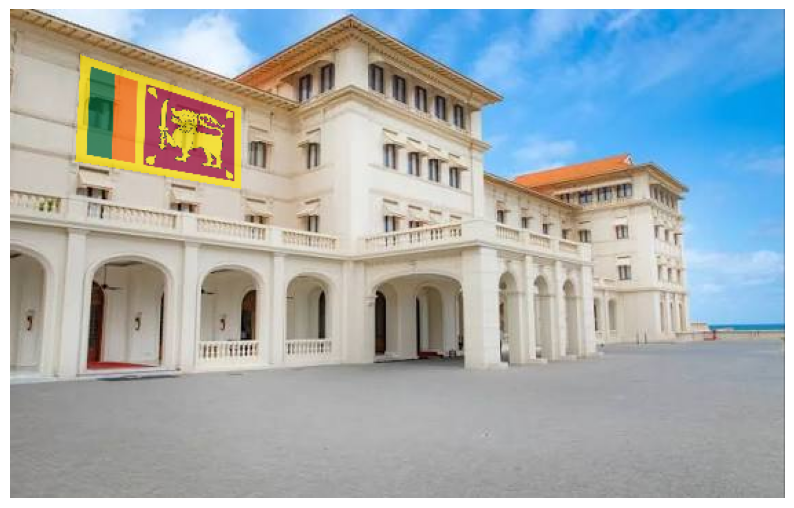

In [63]:
def pick_points(img, n=4, max_w=1200):
    """Click n points on the image: top-left, top-right, bottom-right, bottom-left."""
    s = min(1.0, max_w / img.shape[1])                 # shrink big images to fit the screen
    show = cv.resize(img, None, fx=s, fy=s)
    pts = []
    def click(event, x, y, flags, param):
        if event == cv.EVENT_LBUTTONDOWN and len(pts) < n:
            pts.append([x / s, y / s])                 # store in original-image coordinates
            cv.circle(show, (x, y), 5, (0, 0, 255), -1)
            cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.imshow('click 4 corners (TL, TR, BR, BL)', show)
    cv.setMouseCallback('click 4 corners (TL, TR, BR, BL)', click)
    while len(pts) < n:
        cv.waitKey(20)
    cv.waitKey(300); cv.destroyAllWindows()
    return np.float32(pts)

def superimpose(arch, flag, alpha=0.7):
    h, w = flag.shape[:2]
    src = np.float32([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]])   # flag corners
    dst = pick_points(arch)                                              # clicked corners
    H, _ = cv.findHomography(src, dst)                 # flag plane -> building plane
    size = (arch.shape[1], arch.shape[0])
    warped = cv.warpPerspective(flag, H, size)
    mask = cv.warpPerspective(np.ones((h, w), np.float32), H, size)[..., None]
    out = arch * (1 - alpha * mask) + warped * (alpha * mask)
    return H, out.astype(np.uint8)

pairs = [(r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\Empty_Board_2.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\advertisment.jfif'),
         (r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\galle face hotel.jfif', r'C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\sl_flag.jpg')]   # change to your files

for a, f in pairs:
    arch, flag = cv.imread(a), cv.imread(f)
    assert arch is not None and flag is not None, 'check the image paths'
    H, out = superimpose(arch, flag)
    print('H =\n', np.round(H, 3))
    plt.figure(figsize=(10, 7)); plt.imshow(cv.cvtColor(out, cv.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

# You may explain the (non-technical) rationale of your choice

## 4

Detected 14272 SIFT keypoints on template: C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AECC1.jpg

Processing AAAA1.jpg...
Found 51 good matches after Lowe's ratio test.


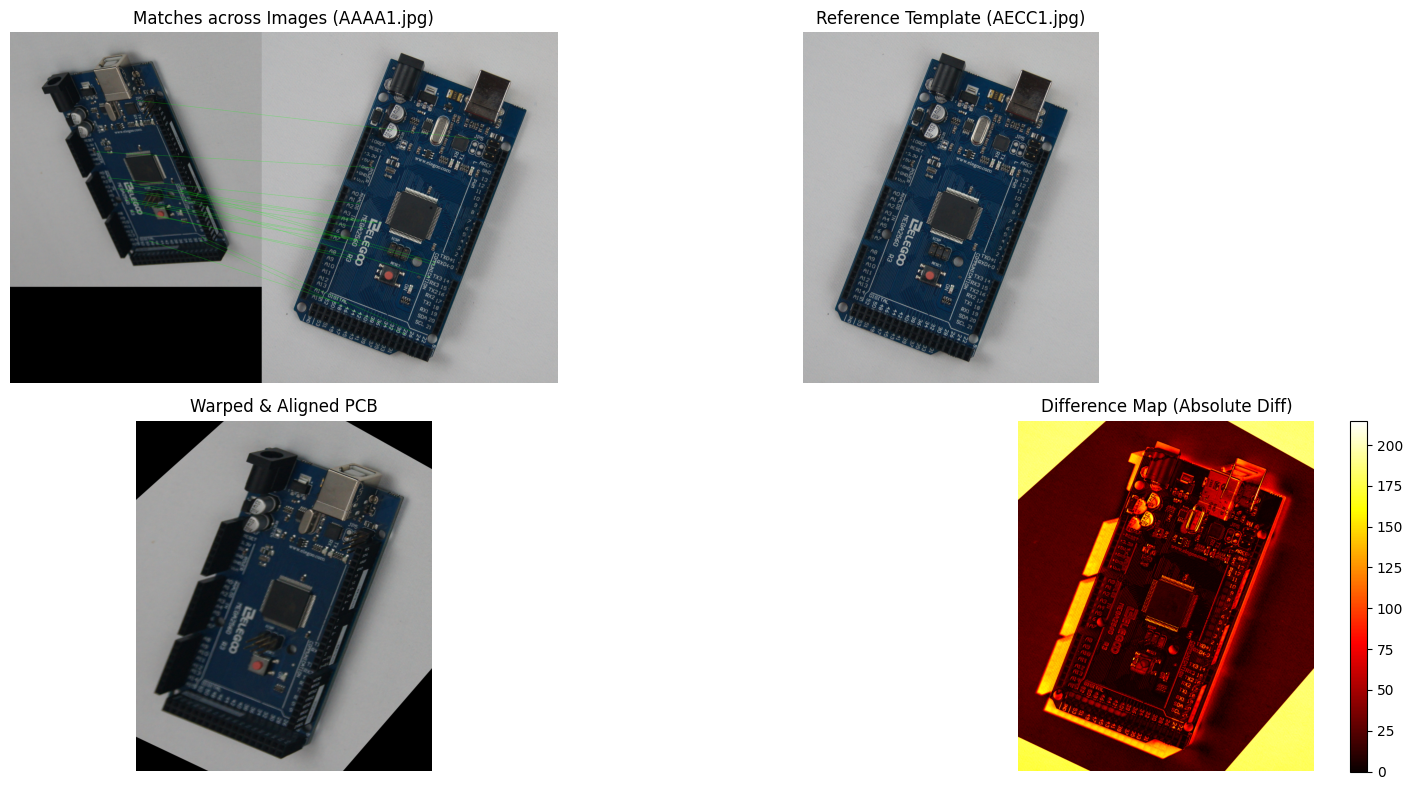


Processing ADAD1.jpg...
Found 369 good matches after Lowe's ratio test.


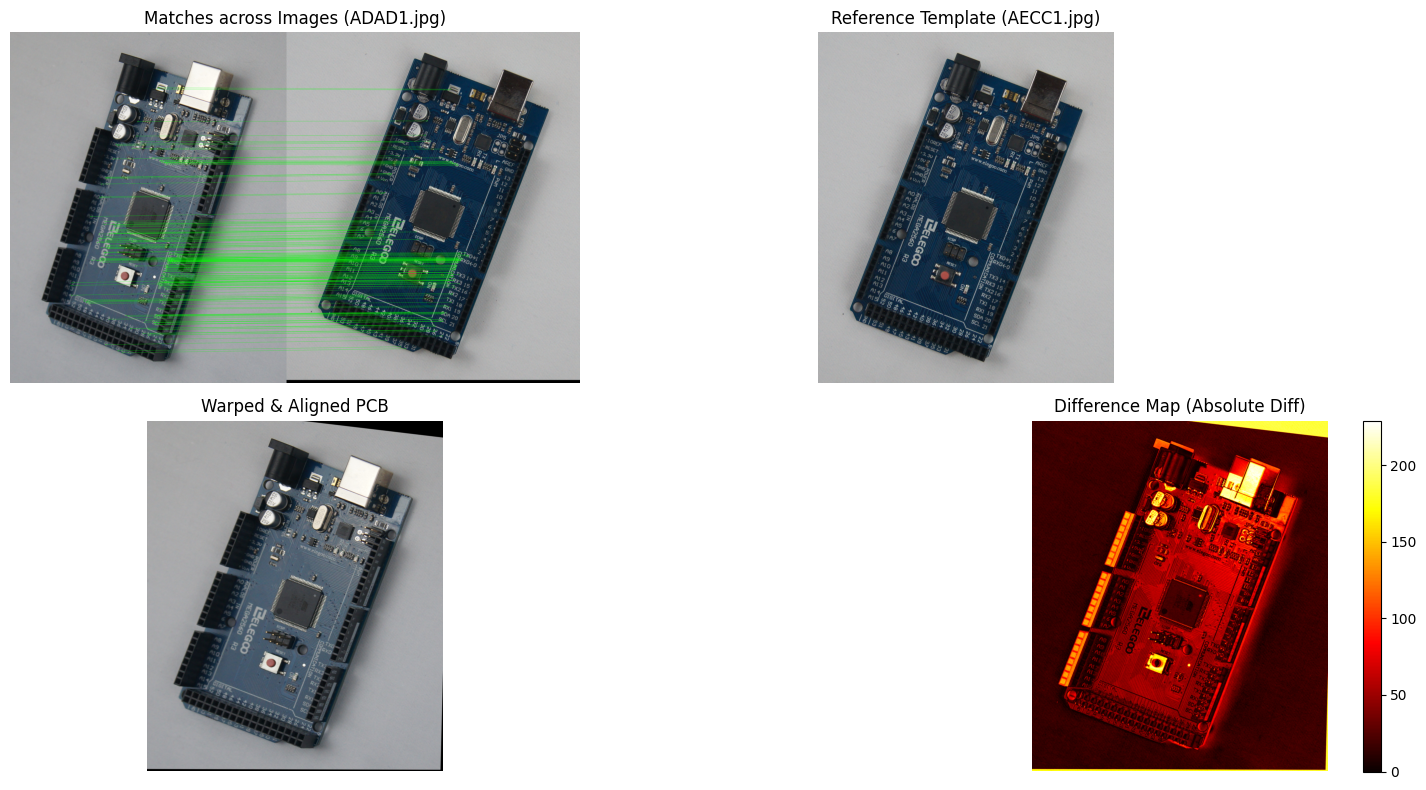

In [ ]:
import glob
import os

def process_pcb_alignment(
    template_path, query_image_paths, output_dir="results"
):
    os.makedirs(output_dir, exist_ok=True)

    
    template_bgr = cv2.imread(template_path)
    if template_bgr is None:
        raise FileNotFoundError(f"Template not found at {template_path}")

    template_gray = cv2.cvtColor(template_bgr, cv2.COLOR_BGR2GRAY)
    h_temp, w_temp = template_gray.shape

    # Initialize SIFT detector
    sift = cv2.SIFT_create()
    kp_temp, des_temp = sift.detectAndCompute(template_gray, None)
    print(
        f"Detected {len(kp_temp)} SIFT keypoints on template: {template_path}"
    )

    # BFMatcher with L2 distance for SIFT
    bf = cv2.BFMatcher(cv2.NORM_L2)

    
    for img_path in query_image_paths:
        base_name = os.path.basename(img_path)
        print(f"\nProcessing {base_name}...")

        query_bgr = cv2.imread(img_path)
        if query_bgr is None:
            print(f"Failed to load {img_path}. Skipping.")
            continue

        query_gray = cv2.cvtColor(query_bgr, cv2.COLOR_BGR2GRAY)

        # (a) Detect SIFT on query image
        kp_query, des_query = sift.detectAndCompute(query_gray, None)

        if des_query is None or len(des_query) < 4:
            print(f"Not enough features found in {base_name}.")
            continue

        
        # k=2 for Lowe's ratio test
        raw_matches = bf.knnMatch(des_query, des_temp, k=2)

        # Apply Lowe's ratio test (0.75 threshold)
        good_matches = []
        for m, n in raw_matches:
            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

        print(
            f"Found {len(good_matches)} good matches after Lowe's ratio test."
        )

        if len(good_matches) < 4:
            print(
                f"Insufficient matches to compute Homography for {base_name}."
            )
            continue

        # Extract coordinates of matched keypoints
        # Note: queryIdx belongs to query_gray, trainIdx belongs to template_gray
        pts_query = np.float32(
            [kp_query[m.queryIdx].pt for m in good_matches]
        ).reshape(-1, 1, 2)
        pts_temp = np.float32(
            [kp_temp[m.trainIdx].pt for m in good_matches]
        ).reshape(-1, 1, 2)

        # Find Homography mapping query image -> template image coordinates
        H, mask = cv2.findHomography(pts_query, pts_temp, cv2.RANSAC, 5.0)

        if H is None:
            print(f"Homography computation failed for {base_name}.")
            continue

        # Draw inlier matches
        matches_mask = mask.ravel().tolist()
        draw_params = dict(
            matchColor=(0, 255, 0),  # draw matches in green
            singlePointColor=None,
            matchesMask=matches_mask,  # draw only RANSAC inliers
            flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS,
        )
        img_matches = cv2.drawMatches(
            query_bgr,
            kp_query,
            template_bgr,
            kp_temp,
            good_matches,
            None,
            **draw_params,
        )

        
        # Warp query to align with template dimensions (w_temp, h_temp)
        aligned_bgr = cv2.warpPerspective(query_bgr, H, (w_temp, h_temp))
        aligned_gray = cv2.cvtColor(aligned_bgr, cv2.COLOR_BGR2GRAY)

        # Optional: slight blur before differencing to suppress micro-misalignment edges
        blur_temp = cv2.GaussianBlur(template_gray, (3, 3), 0)
        blur_aligned = cv2.GaussianBlur(aligned_gray, (3, 3), 0)

        # Absolute pixel-wise difference
        diff_gray = cv2.absdiff(blur_temp, blur_aligned)

        # Threshold to highlight defects/changes clearly
        _, diff_thresh = cv2.threshold(
            diff_gray, 40, 255, cv2.THRESH_BINARY
        )

        
        # Save images to disk
        name_no_ext = os.path.splitext(base_name)[0]
        cv2.imwrite(
            os.path.join(output_dir, f"{name_no_ext}_matches.jpg"), img_matches
        )
        cv2.imwrite(
            os.path.join(output_dir, f"{name_no_ext}_aligned.jpg"), aligned_bgr
        )
        cv2.imwrite(
            os.path.join(output_dir, f"{name_no_ext}_diff.jpg"), diff_gray
        )
        cv2.imwrite(
            os.path.join(output_dir, f"{name_no_ext}_diff_thresh.jpg"),
            diff_thresh,
        )

        # Plot using Matplotlib for reporting
        plt.figure(figsize=(16, 8))

        plt.subplot(2, 2, 1)
        plt.title(f"Matches across Images ({base_name})")
        plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
        plt.axis("off")

        plt.subplot(2, 2, 2)
        plt.title("Reference Template (AECC1.jpg)")
        plt.imshow(cv2.cvtColor(template_bgr, cv2.COLOR_BGR2RGB))
        plt.axis("off")

        plt.subplot(2, 2, 3)
        plt.title("Warped & Aligned PCB")
        plt.imshow(cv2.cvtColor(aligned_bgr, cv2.COLOR_BGR2RGB))
        plt.axis("off")

        plt.subplot(2, 2, 4)
        plt.title("Difference Map (Absolute Diff)")
        plt.imshow(diff_gray, cmap="hot")
        plt.colorbar(fraction=0.046, pad=0.04)
        plt.axis("off")

        plt.tight_layout()
        plt.savefig(
            os.path.join(output_dir, f"{name_no_ext}_summary.png"), dpi=200
        )
        plt.show()
        
if __name__ == "__main__":
    # 1. Set your template image filename
    TEMPLATE_IMAGE = r"C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AECC1.jpg"

    # 2. Provide the rest of your PCB images:
    # Option A: List them manually
    test_pcb_images = [r"C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\AAAA1.jpg", r"C:\Users\USER\Desktop\5th Semester\CV\Assignment 2\EN3160-Assignment-2\a2images\a2images\pcbs\ADAD1.jpg"]

    # Option B: Or automatically pick all other images in the current folder
    # all_images = glob.glob("*.jpg") + glob.glob("*.png")
    # test_pcb_images = [f for f in all_images if os.path.basename(f) != os.path.basename(TEMPLATE_IMAGE)]

    process_pcb_alignment(TEMPLATE_IMAGE, test_pcb_images)